In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy  as np
import math, json, os
pd.set_option('display.max_columns', None)

In [2]:
OPTIONS  = json.loads(open('info.json', 'rb').read())
TARGETS  = OPTIONS['target_var']
N_STATES = OPTIONS['n_states']
dt = OPTIONS['dt']

TEST   = json.loads(open('../../info.json', 'r').read()).get('test', 1)
SOURCE = f'../../Dataset/test{TEST}/results/corrected.csv'

print('SOURCE:', SOURCE)
OPTIONS

SOURCE: ../../Dataset/test1/results/corrected.csv


{'target_var': ['pitch', 'roll'],
 'seevar': 'wx',
 'n_states': 30,
 'k_cv': 5,
 'model': 'linear_regression',
 'n_iter': 15000,
 'dt': 0.1}

# IMPORTANDO DADOS
- Saída do `2 - Correction`: acelerômetro e giroscópio filtrados e corrigidos nos eixos do navio, com a atitude da referência como rótulo

In [3]:
SENSORS = ['ax', 'ay', 'az', 'wx', 'wy', 'wz']
ANGLES  = ['pitch', 'roll', 'yaw']

# ENTRADA SAI DO MRU CORRIGIDO, RÓTULO SAI DA REFERÊNCIA
df = pd.read_csv(SOURCE)
df = df[['time', 'static'] + SENSORS + [f'ref_{var}' for var in ANGLES]].rename(columns={f'ref_{var}': var for var in ANGLES})
df

,time,static,ax,ay,az,wx,wy,wz,pitch,roll,yaw
0,0.0,False,0.212621,10.733956,0.541538,-48.149620,0.724096,0.600353,0.304871,-71.390541,2.771970
1,0.1,False,0.236557,11.498772,0.493097,-58.326192,0.580323,0.383267,0.337243,-76.661753,2.723841
2,0.2,False,0.121950,12.716274,1.420537,-67.640523,0.887947,-0.479057,0.366750,-82.677810,2.667691
3,0.3,False,0.233087,12.446751,0.857032,-67.714281,0.680188,0.909507,0.387721,-89.209529,2.743322
4,0.4,False,0.287146,12.369719,0.464970,-66.916715,1.010186,0.684956,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,0.274240,9.755749,0.368467,-0.108781,-0.135746,0.175447,1.644962,-92.131613,6.371291
1796,279.5,True,0.276545,9.723646,0.355675,-0.093128,-0.053090,0.011786,1.645535,-92.131613,6.371291
1797,279.6,True,0.281426,9.763755,0.351283,-0.116659,-0.223368,-0.467062,1.644962,-92.131613,6.371291
1798,279.7,True,0.281160,9.792971,0.393126,0.093310,-0.042774,-0.151325,1.645535,-92.131613,6.377020


# PERÍODO DE AMOSTRAGEM
- A janela de estados vale na taxa do treino, o `dt` do `info.json`: é nessa taxa que o firmware anda o modelo, e um ensaio mais rápido é decimado aqui

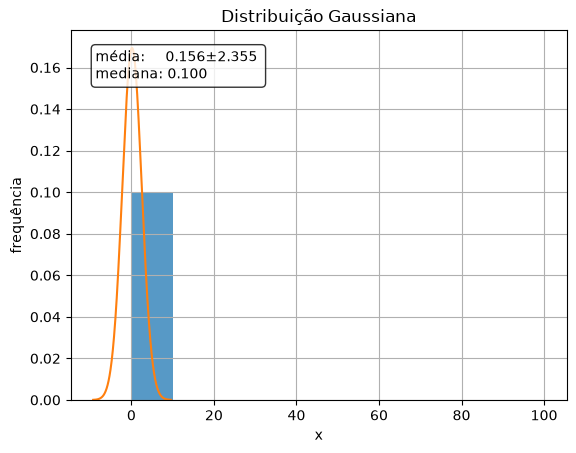

1800 amostras na grade de 0.1 s


,time,static,ax,ay,az,wx,wy,wz,pitch,roll,yaw
0,0.0,False,0.212621,10.733956,0.541538,-48.149620,0.724096,0.600353,0.304871,-71.390541,2.771970
1,0.1,False,0.236557,11.498772,0.493097,-58.326192,0.580323,0.383267,0.337243,-76.661753,2.723841
2,0.2,False,0.121950,12.716274,1.420537,-67.640523,0.887947,-0.479057,0.366750,-82.677810,2.667691
3,0.3,False,0.233087,12.446751,0.857032,-67.714281,0.680188,0.909507,0.387721,-89.209529,2.743322
4,0.4,False,0.287146,12.369719,0.464970,-66.916715,1.010186,0.684956,0.442381,-95.913135,2.624720
...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,0.274240,9.755749,0.368467,-0.108781,-0.135746,0.175447,1.644962,-92.131613,6.371291
1796,279.5,True,0.276545,9.723646,0.355675,-0.093128,-0.053090,0.011786,1.645535,-92.131613,6.371291
1797,279.6,True,0.281426,9.763755,0.351283,-0.116659,-0.223368,-0.467062,1.644962,-92.131613,6.371291
1798,279.7,True,0.281160,9.792971,0.393126,0.093310,-0.042774,-0.151325,1.645535,-92.131613,6.377020


In [4]:
def gaussian(data):
    data  = np.array(data)
    n     = data.shape[0]
    mu    = data.mean()
    sigma = data.std()

    x  = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
    y  = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x - mu)/sigma)**2)
    plt.title(f'Distribuição Gaussiana')
    plt.hist(data, density=True, alpha=0.75)
    plt.plot(x, y)

    text = f'média:     {mu:.3f}±{sigma:.3f} \nmediana: {np.median(data):.3f}'
    opts = dict(boxstyle='round', facecolor='white', alpha=0.8)
    plt.text(0.05, 0.95, text, transform=plt.gca().transAxes, verticalalignment='top', bbox=opts)
    plt.xlabel('x'); plt.ylabel('frequência'); plt.grid()

# GRADE E LEITURAS ARREDONDADAS NA MESMA CASA: SEM ISSO O RUÍDO DE FLOAT (1e-14) FAZ O merge_asof SEGURAR A AMOSTRA ANTERIOR
def normalizePeriod(df, key, dt=0.15):
    df = df.copy().sort_values(key)
    df[key] = (df[key] - df[key].iloc[0]).round(10)

    n = int(np.floor(df[key].iloc[-1] / dt)) + 1
    newAxis = np.round(np.linspace(0, dt*(n-1), n), 10)
    target  = pd.DataFrame({key: newAxis})
    return pd.merge_asof(target, df, on=key, direction='nearest', tolerance=dt/2).dropna().reset_index(drop=True)


time = df.time.diff()[1:].to_numpy()

gaussian(time); plt.show()
df = normalizePeriod(df, 'time', dt).astype({'static': bool})
print(len(df), 'amostras na grade de', dt, 's')
df

# VISUALIZAÇÃO DOS DADOS

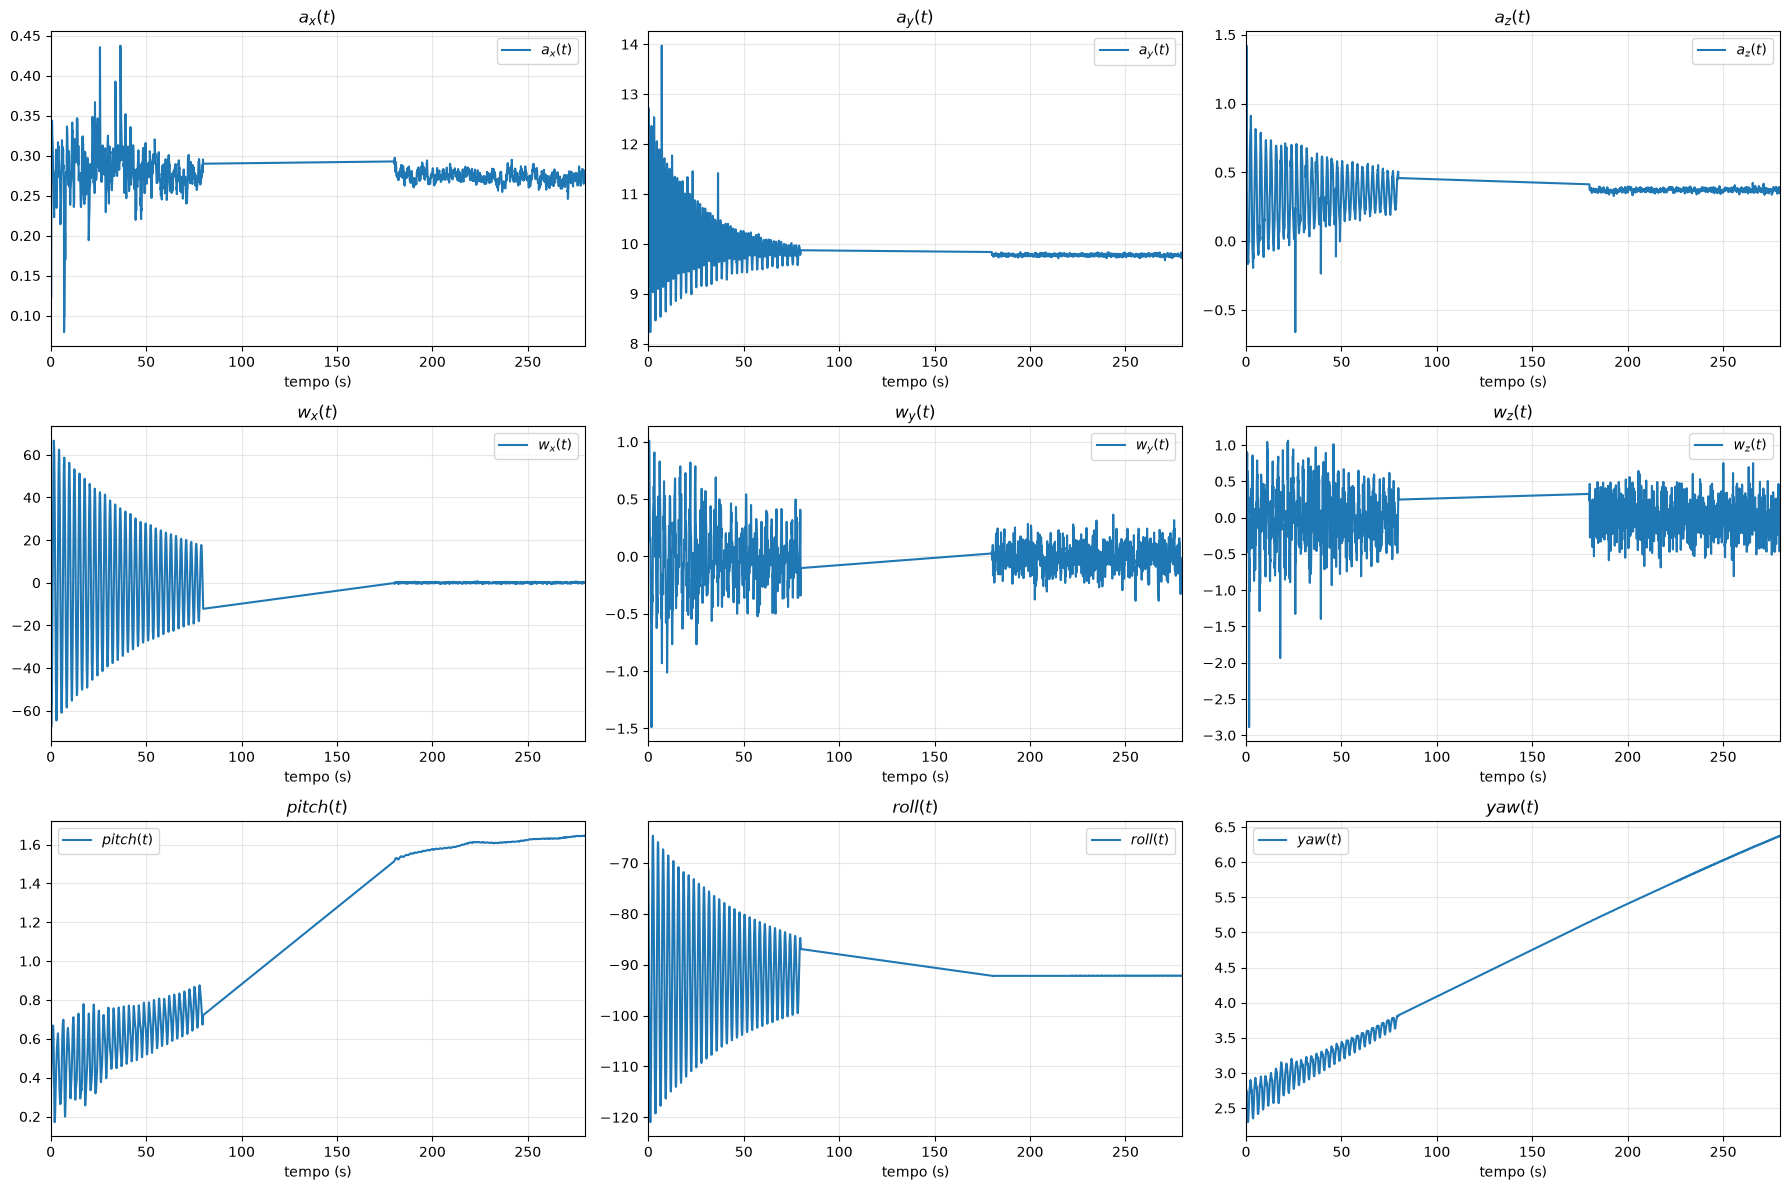

In [5]:
# GRADE DE SUBPLOTS RECORTADA POR FRAÇÃO DO TEMPO TOTAL
def compareAxis(time, data, limits=(0, 1), yLim=None):
    t_min, t_max = time.min(), time.max()
    delta = (t_max - t_min)

    start_time = t_min + (delta * limits[0])
    end_time   = t_min + (delta * limits[1])

    count   = len(data.keys())
    numCols = 3 if count >= 3 else count
    numRows = math.ceil(count / numCols)
    plt.figure(figsize=(6*numCols, 4*numRows))

    for i, (key, values) in enumerate(data.items()):
        mask = (time >= start_time) & (time <= end_time)

        plt.subplot(numRows, numCols, i+1)
        plt.plot(time[mask], values[mask], label=key)

        plt.xlim(start_time, end_time)
        if yLim: plt.ylim(yLim)
        plt.title(key); plt.xlabel('tempo (s)')
        plt.grid(alpha=0.3); plt.legend()

    plt.tight_layout()
    plt.show()


# PAINEL PADRÃO: GIROSCÓPIO, ACELERÔMETRO E ATITUDE DE REFERÊNCIA
def plotAll(df, limits=(0, 1)):
    compareAxis(df.time, {
        '$a_x(t)$': df.ax, '$a_y(t)$': df.ay, '$a_z(t)$': df.az,
        '$w_x(t)$': df.wx, '$w_y(t)$': df.wy, '$w_z(t)$': df.wz,
        '$pitch(t)$': df.pitch, '$roll(t)$': df.roll, '$yaw(t)$': df.yaw
    }, limits)


plotAll(df, limits=(0, 1))

# VALORES PASSADOS
- Cada amostra leva os `n_states` instantes anteriores de cada sensor, sem atravessar o buraco da gravação

In [6]:
# JANELA DESLIZANTE: y(n), y(n-1) ... y(n-N+1) COMO COLUNAS, SEM ATRAVESSAR O BURACO ENTRE TRECHOS
def getStates(df, key, var='y', n=10):
    table   = df.copy()
    segment = (table.time.diff() > 1.5*dt).cumsum()
    table[f'{var}'] = table[key]

    for i in range(1, n):
        table[f'{var}(n-{i})'] = table[key].groupby(segment).shift(i)

    columns = [f'{var}'] + [f'{var}(n-{i})' for i in range(1, n)]
    return table[columns]


print('n_states:', N_STATES)
xData = pd.concat([getStates(df, var, var=var, n=N_STATES) for var in ['wx', 'wy', 'wz', 'ax', 'ay', 'az']], axis=1)
xData

n_states: 30


,wx,wx(n-1),wx(n-2),wx(n-3),wx(n-4),wx(n-5),wx(n-6),wx(n-7),wx(n-8),wx(n-9),wx(n-10),wx(n-11),wx(n-12),wx(n-13),wx(n-14),wx(n-15),wx(n-16),wx(n-17),wx(n-18),wx(n-19),wx(n-20),wx(n-21),wx(n-22),wx(n-23),wx(n-24),wx(n-25),wx(n-26),wx(n-27),wx(n-28),wx(n-29),wy,wy(n-1),wy(n-2),wy(n-3),wy(n-4),wy(n-5),wy(n-6),wy(n-7),wy(n-8),wy(n-9),wy(n-10),wy(n-11),wy(n-12),wy(n-13),wy(n-14),wy(n-15),wy(n-16),wy(n-17),wy(n-18),wy(n-19),wy(n-20),wy(n-21),wy(n-22),wy(n-23),wy(n-24),wy(n-25),wy(n-26),wy(n-27),wy(n-28),wy(n-29),wz,wz(n-1),wz(n-2),wz(n-3),wz(n-4),wz(n-5),wz(n-6),wz(n-7),wz(n-8),wz(n-9),wz(n-10),wz(n-11),wz(n-12),wz(n-13),wz(n-14),wz(n-15),wz(n-16),wz(n-17),wz(n-18),wz(n-19),wz(n-20),wz(n-21),wz(n-22),wz(n-23),wz(n-24),wz(n-25),wz(n-26),wz(n-27),wz(n-28),wz(n-29),ax,ax(n-1),ax(n-2),ax(n-3),ax(n-4),ax(n-5),ax(n-6),ax(n-7),ax(n-8),ax(n-9),ax(n-10),ax(n-11),ax(n-12),ax(n-13),ax(n-14),ax(n-15),ax(n-16),ax(n-17),ax(n-18),ax(n-19),ax(n-20),ax(n-21),ax(n-22),ax(n-23),ax(n-24),ax(n-25),ax(n-26),ax(n-27),ax(n-28),ax(n-29),ay,ay(n-1),ay(n-2),ay(n-3),ay(n-4),ay(n-5),ay(n-6),ay(n-7),ay(n-8),ay(n-9),ay(n-10),ay(n-11),ay(n-12),ay(n-13),ay(n-14),ay(n-15),ay(n-16),ay(n-17),ay(n-18),ay(n-19),ay(n-20),ay(n-21),ay(n-22),ay(n-23),ay(n-24),ay(n-25),ay(n-26),ay(n-27),ay(n-28),ay(n-29),az,az(n-1),az(n-2),az(n-3),az(n-4),az(n-5),az(n-6),az(n-7),az(n-8),az(n-9),az(n-10),az(n-11),az(n-12),az(n-13),az(n-14),az(n-15),az(n-16),az(n-17),az(n-18),az(n-19),az(n-20),az(n-21),az(n-22),az(n-23),az(n-24),az(n-25),az(n-26),az(n-27),az(n-28),az(n-29)
0,-48.149620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.724096,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.600353,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.212621,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.733956,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.541538,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-58.326192,-48.149620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.580323,0.724096,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.383267,0.600353,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.236557,0.212621,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.498772,10.733956,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.493097,0.541538,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-67.640523,-58.326192,-48.149620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.887947,0.580323,0.724096,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.479057,0.383267,0.600353,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.121950,0.236557,0.212621,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.716274,11.498772,10.733956,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.420537,0.493097,0.541538,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,-67.714281,-67.640523,-58.326192,-48.149620,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

In [7]:
os.makedirs('Backup', exist_ok=True)
df = pd.concat([df.time, xData, df[TARGETS]], axis=1).dropna().reset_index(drop=True)
df.to_csv('Backup/model.csv', index=None)
df

,time,wx,wx(n-1),wx(n-2),wx(n-3),wx(n-4),wx(n-5),wx(n-6),wx(n-7),wx(n-8),wx(n-9),wx(n-10),wx(n-11),wx(n-12),wx(n-13),wx(n-14),wx(n-15),wx(n-16),wx(n-17),wx(n-18),wx(n-19),wx(n-20),wx(n-21),wx(n-22),wx(n-23),wx(n-24),wx(n-25),wx(n-26),wx(n-27),wx(n-28),wx(n-29),wy,wy(n-1),wy(n-2),wy(n-3),wy(n-4),wy(n-5),wy(n-6),wy(n-7),wy(n-8),wy(n-9),wy(n-10),wy(n-11),wy(n-12),wy(n-13),wy(n-14),wy(n-15),wy(n-16),wy(n-17),wy(n-18),wy(n-19),wy(n-20),wy(n-21),wy(n-22),wy(n-23),wy(n-24),wy(n-25),wy(n-26),wy(n-27),wy(n-28),wy(n-29),wz,wz(n-1),wz(n-2),wz(n-3),wz(n-4),wz(n-5),wz(n-6),wz(n-7),wz(n-8),wz(n-9),wz(n-10),wz(n-11),wz(n-12),wz(n-13),wz(n-14),wz(n-15),wz(n-16),wz(n-17),wz(n-18),wz(n-19),wz(n-20),wz(n-21),wz(n-22),wz(n-23),wz(n-24),wz(n-25),wz(n-26),wz(n-27),wz(n-28),wz(n-29),ax,ax(n-1),ax(n-2),ax(n-3),ax(n-4),ax(n-5),ax(n-6),ax(n-7),ax(n-8),ax(n-9),ax(n-10),ax(n-11),ax(n-12),ax(n-13),ax(n-14),ax(n-15),ax(n-16),ax(n-17),ax(n-18),ax(n-19),ax(n-20),ax(n-21),ax(n-22),ax(n-23),ax(n-24),ax(n-25),ax(n-26),ax(n-27),ax(n-28),ax(n-29),ay,ay(n-1),ay(n-2),ay(n-3),ay(n-4),ay(n-5),ay(n-6),ay(n-7),ay(n-8),ay(n-9),ay(n-10),ay(n-11),ay(n-12),ay(n-13),ay(n-14),ay(n-15),ay(n-16),ay(n-17),ay(n-18),ay(n-19),ay(n-20),ay(n-21),ay(n-22),ay(n-23),ay(n-24),ay(n-25),ay(n-26),ay(n-27),ay(n-28),ay(n-29),az,az(n-1),az(n-2),az(n-3),az(n-4),az(n-5),az(n-6),az(n-7),az(n-8),az(n-9),az(n-10),az(n-11),az(n-12),az(n-13),az(n-14),az(n-15),az(n-16),az(n-17),az(n-18),az(n-19),az(n-20),az(n-21),az(n-22),az(n-23),az(n-24),az(n-25),az(n-26),az(n-27),az(n-28),az(n-29),pitch,roll
0,2.9,-61.920813,-55.741575,-46.470145,-35.693011,-22.056448,-7.449682,7.779116,21.814010,36.167482,47.960320,57.331324,63.109830,65.306240,66.645109,60.837035,52.901735,41.600044,28.785473,13.811610,-1.063215,-16.365014,-30.843730,-43.737273,-54.816846,-62.016701,-66.916715,-67.714281,-67.640523,-58.326192,-48.149620,0.497866,0.609822,0.484973,0.457005,0.426192,0.356738,-0.132528,-0.390992,-0.342256,-0.500054,-0.551983,-0.707630,-1.270942,-1.489054,-0.500102,-0.571204,-0.340537,-0.177339,0.058896,0.163482,0.166410,0.138733,0.451969,0.636408,0.910216,1.010186,0.680188,0.887947,0.580323,0.724096,-0.421425,-0.090222,0.321702,0.394801,0.052594,0.282653,-0.150528,-0.021459,-0.211970,-0.436061,-0.197064,-1.017802,-0.553450,-2.888154,-0.700860,-0.398312,-0.255850,-0.094459,0.439285,0.581094,0.640487,0.265883,0.312155,0.890830,0.669983,0.684956,0.909507,-0.479057,0.383267,0.600353,0.304097,0.307499,0.298450,0.265490,0.275538,0.257603,0.260737,0.263048,0.278880,0.277972,0.261094,0.223052,0.232473,0.248035,0.267357,0.268490,0.277107,0.288107,0.298408,0.317306,0.318562,0.332336,0.343541,0.317529,0.299584,0.287146,0.233087,0.121950,0.236557,0.212621,11.985594,11.493782,10.634560,9.955443,9.340953,9.030429,9.056680,9.497020,10.169419,11.007265,11.636321,12.210281,12.359971,12.082231,11.483373,10.653331,9.724681,8.927149,8.408259,8.228925,8.613208,9.175061,10.163896,11.082797,11.774373,12.369719,12.446751,12.716274,11.498772,10.733956,0.427933,0.597938,0.714168,0.844819,0.911088,0.825853,0.805589,0.769762,0.723475,0.672083,0.533737,0.409543,0.177889,-0.006688,0.036631,-0.039395,-0.097616,-0.156755,-0.139630,-0.165887,-0.166941,-0.159145,-0.118514,0.054353,0.258286,0.464970,0.857032,1.420537,0.493097,0.541538,0.455501,-83.995613
1,3.0,-64.593571,-61.920813,-55.741575,-46.470145,-35.693011,-22.056448,-7.449682,7.779116,21.814010,36.167482,47.960320,57.331324,63.109830,65.306240,66.645109,60.837035,52.901735,41.600044,28.785473,13.811610,-1.063215,-16.365014,-30.843730,-43.737273,-54.816846,-62.016701,-66.916715,-67.714281,-67.640523,-58.326192,0.864253,0.497866,0.609822,0.484973,0.457005,0.426192,0.356738,-0.132528,-0.390992,-0.342256,-0.500054,-0.551983,-0.707630,-1.270942,-1.489054,-0.500102,-0.571204,-0.340537,-0.177339,0.058896,0.163482,0.166410,0.138733,0.451969,0.636408,0.910216,1.010186,0.680188,0.887947,0.580323,0.092382,-0.421425,-0.090222,0.321702,0.394801,0.052594,0.282653,-0.150528,-0.021459,-0.211970,-0.436061,-